In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/exploring-risk-factors-for-cardiovascular-diseas/heart_data.csv


In [2]:
data = pd.read_csv('/kaggle/input/exploring-risk-factors-for-cardiovascular-diseas/heart_data.csv')
data.info()
data.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        70000 non-null  int64  
 1   id           70000 non-null  int64  
 2   age          70000 non-null  int64  
 3   gender       70000 non-null  int64  
 4   height       70000 non-null  int64  
 5   weight       70000 non-null  float64
 6   ap_hi        70000 non-null  int64  
 7   ap_lo        70000 non-null  int64  
 8   cholesterol  70000 non-null  int64  
 9   gluc         70000 non-null  int64  
 10  smoke        70000 non-null  int64  
 11  alco         70000 non-null  int64  
 12  active       70000 non-null  int64  
 13  cardio       70000 non-null  int64  
dtypes: float64(1), int64(13)
memory usage: 7.5 MB


,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
5,5,8,21914,1,151,67.0,120,80,2,2,0,0,0,0
6,6,9,22113,1,157,93.0,130,80,3,1,0,0,1,0
7,7,12,22584,2,178,95.0,130,90,3,3,0,0,1,1
8,8,13,17668,1,158,71.0,110,70,1,1,0,0,1,0
9,9,14,19834,1,164,68.0,110,60,1,1,0,0,0,0


<function matplotlib.pyplot.show(close=None, block=None)>

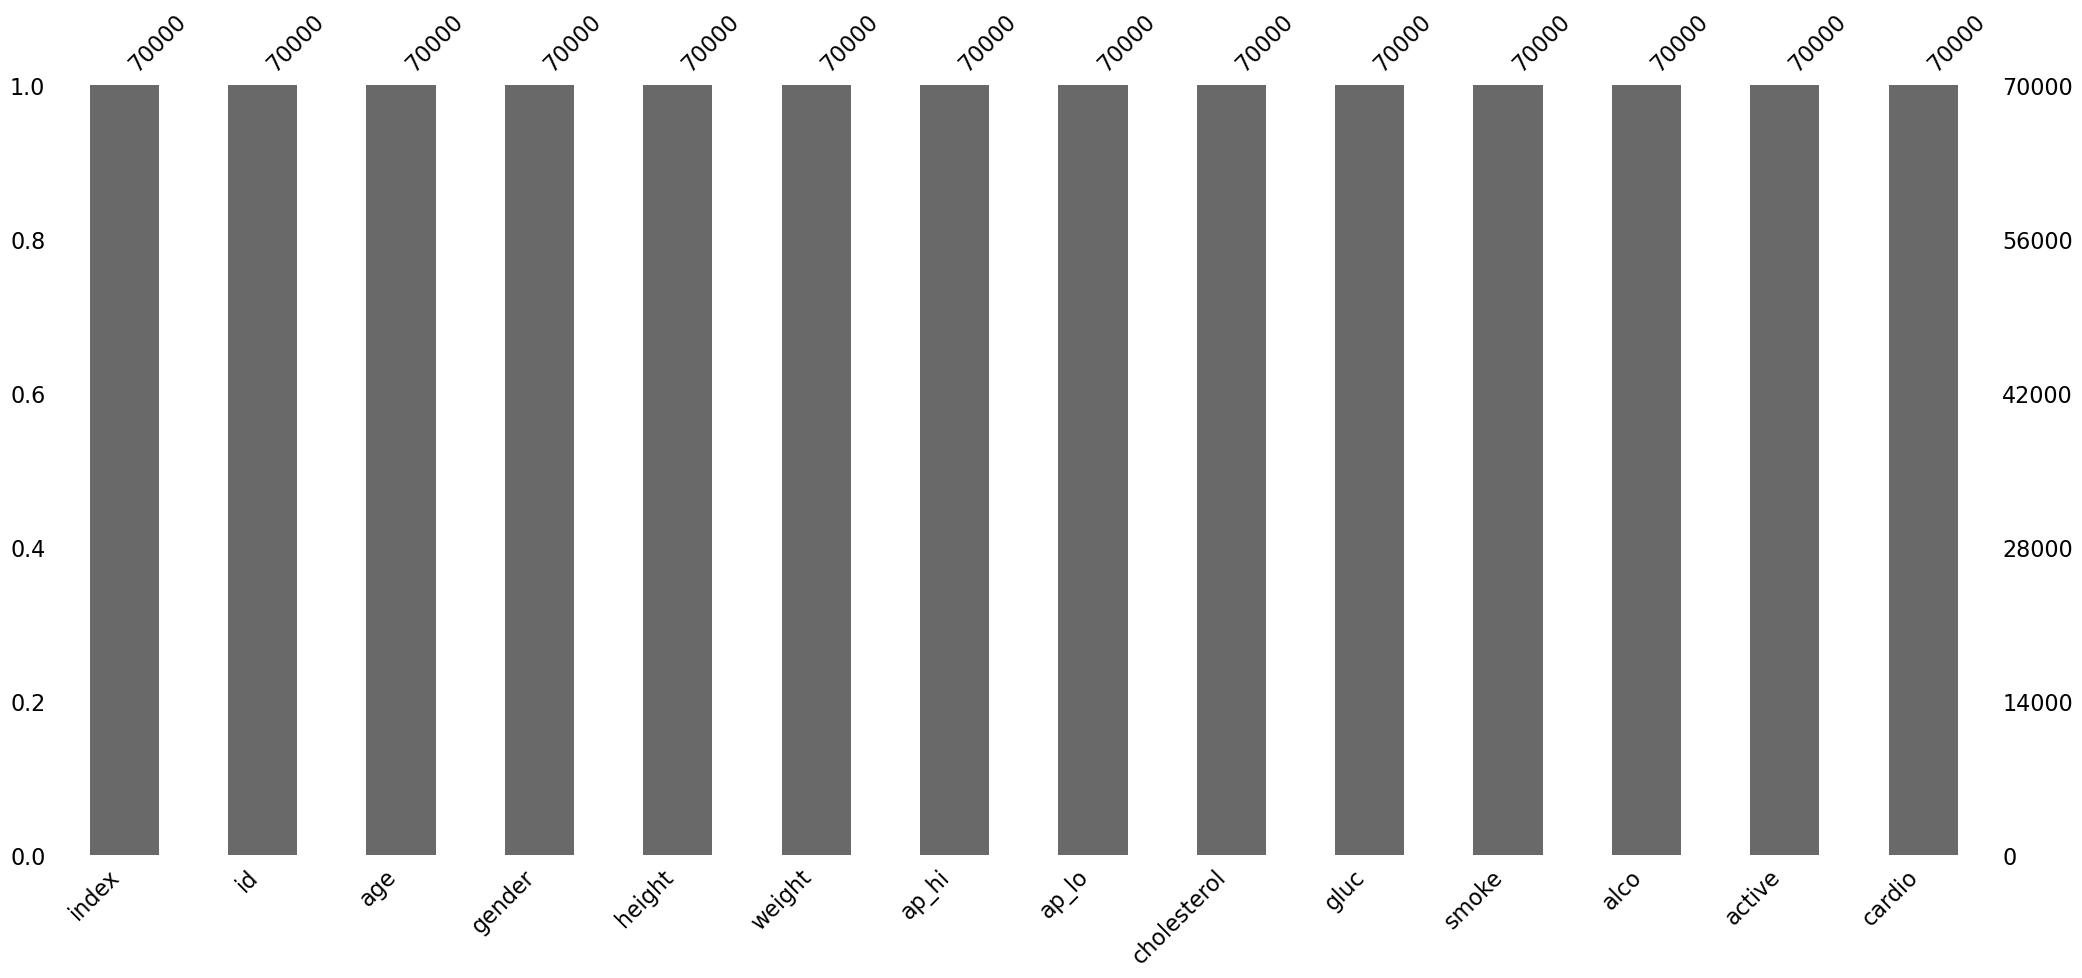

In [3]:
import missingno as msno
import matplotlib.pyplot as plt
msno.bar(data)
plt.show

Text(0.5, 1.0, 'Correlation')

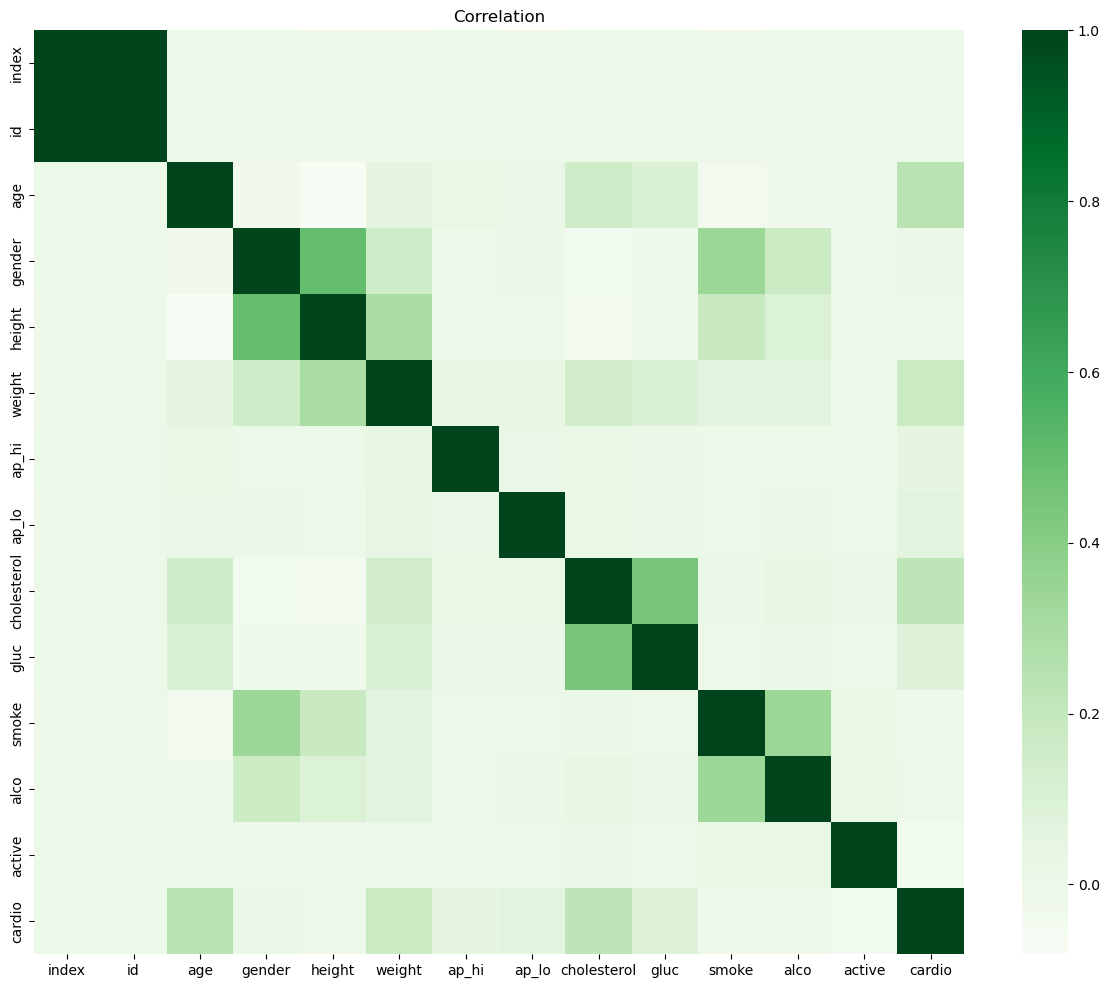

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
corr=data.corr()
fig = plt.figure(figsize=(15,12))
r = sns.heatmap(corr, cmap='Greens')
r.set_title('Correlation')

In [5]:
#cardiovascular range Correlation
corr.sort_values(by=["cardio"], ascending=False).iloc[0].sort_values(ascending=False)

cardio         1.000000
age            0.238159
cholesterol    0.221147
weight         0.181660
gluc           0.089307
ap_lo          0.065719
ap_hi          0.054475
gender         0.008109
index          0.003800
id             0.003799
alco          -0.007330
height        -0.010821
smoke         -0.015486
active        -0.035653
Name: cardio, dtype: float64

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from scipy import stats
import warnings 
warnings.filterwarnings('ignore')

In [7]:
print(data.head(), data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        70000 non-null  int64  
 1   id           70000 non-null  int64  
 2   age          70000 non-null  int64  
 3   gender       70000 non-null  int64  
 4   height       70000 non-null  int64  
 5   weight       70000 non-null  float64
 6   ap_hi        70000 non-null  int64  
 7   ap_lo        70000 non-null  int64  
 8   cholesterol  70000 non-null  int64  
 9   gluc         70000 non-null  int64  
 10  smoke        70000 non-null  int64  
 11  alco         70000 non-null  int64  
 12  active       70000 non-null  int64  
 13  cardio       70000 non-null  int64  
dtypes: float64(1), int64(13)
memory usage: 7.5 MB
   index  id    age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  \
0      0   0  18393       2     168    62.0    110     80            1     1   
1      1

In [8]:
data['gluc'].unique()

array([1, 2, 3])

In [9]:
#Mengubah dari usia per-hari menjadi per-tahun
data['age_year'] = round(data['age']/365,0)

data

,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_year
0,0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.0
1,1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.0
2,2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,52.0
3,3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.0
4,4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,48.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0,53.0
69996,69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1,62.0
69997,69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1,52.0
69998,69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1,61.0


In [10]:
data_cols = ['index', 'id']
data.drop(data_cols,axis=1, inplace = True)
data

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_year
0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.0
2,18857,1,165,64.0,130,70,3,1,0,0,0,1,52.0
3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.0
4,17474,1,156,56.0,100,60,1,1,0,0,0,0,48.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,19240,2,168,76.0,120,80,1,1,1,0,1,0,53.0
69996,22601,1,158,126.0,140,90,2,2,0,0,1,1,62.0
69997,19066,2,183,105.0,180,90,3,1,0,1,0,1,52.0
69998,22431,1,163,72.0,135,80,1,2,0,0,0,1,61.0


In [11]:
data['gender']

0        2
1        1
2        1
3        2
4        1
        ..
69995    2
69996    1
69997    2
69998    1
69999    1
Name: gender, Length: 70000, dtype: int64

In [12]:
data.describe()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_year
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700,53.338686
std,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003,6.765294
min,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,30.000000
25%,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,48.000000
50%,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,54.000000
75%,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.000000
max,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,65.000000


In [13]:
data.isna().sum()

age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
age_year       0
dtype: int64

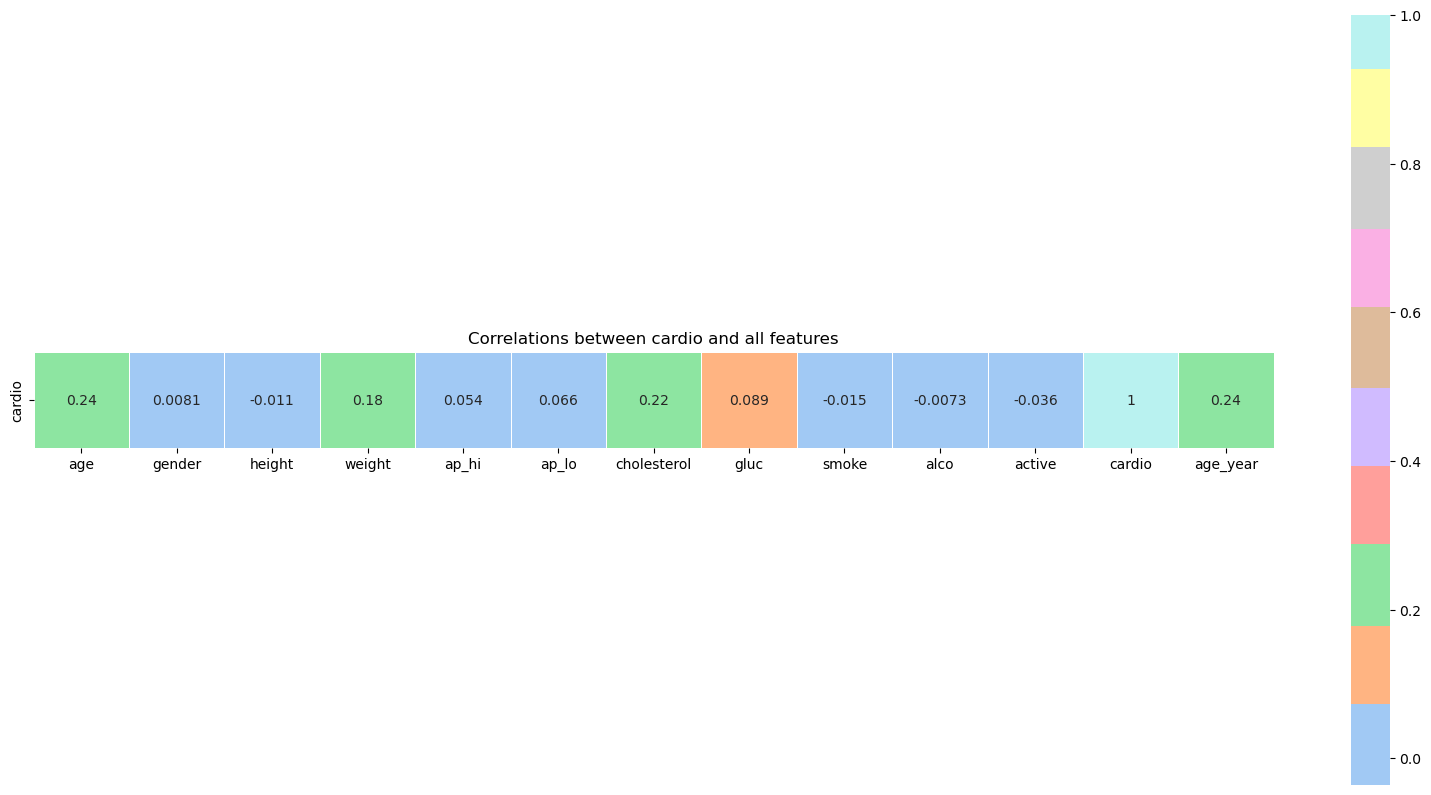

In [14]:
data_corr = data.corr()[['cardio']]
plt.figure(figsize = (20,10))
palette = sns.color_palette('pastel')
sns.heatmap(data_corr.T,annot = True, center = 0.5, vmax=1,
           square=True, linewidths=.6, cmap= palette)
plt.title('Correlations between cardio and all features')
plt.show()

In [15]:
#Make a numeric data 
data_num = data[['height', 'weight', 'ap_hi', 'ap_lo', 'age_year']]

data_num

,height,weight,ap_hi,ap_lo,age_year
0,168,62.0,110,80,50.0
1,156,85.0,140,90,55.0
2,165,64.0,130,70,52.0
3,169,82.0,150,100,48.0
4,156,56.0,100,60,48.0
...,...,...,...,...,...
69995,168,76.0,120,80,53.0
69996,158,126.0,140,90,62.0
69997,183,105.0,180,90,52.0
69998,163,72.0,135,80,61.0


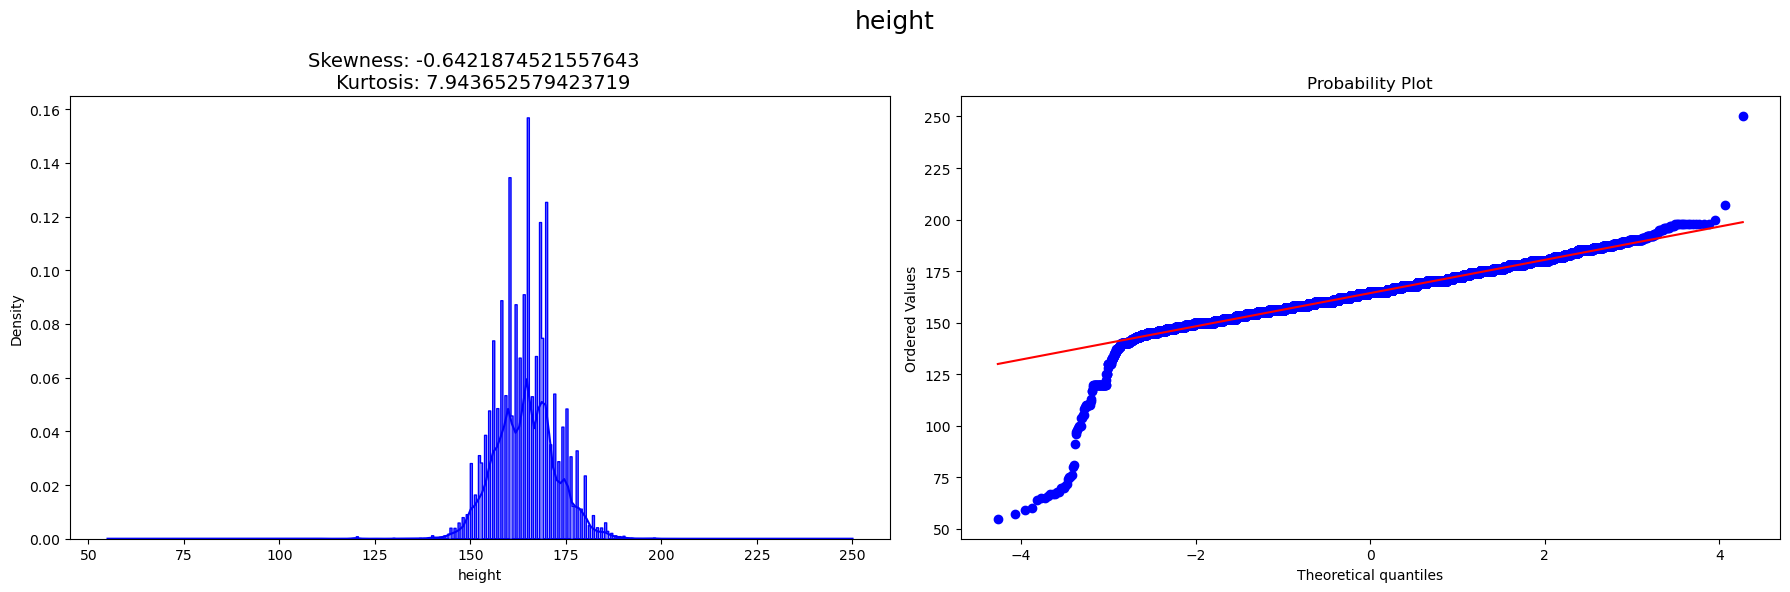

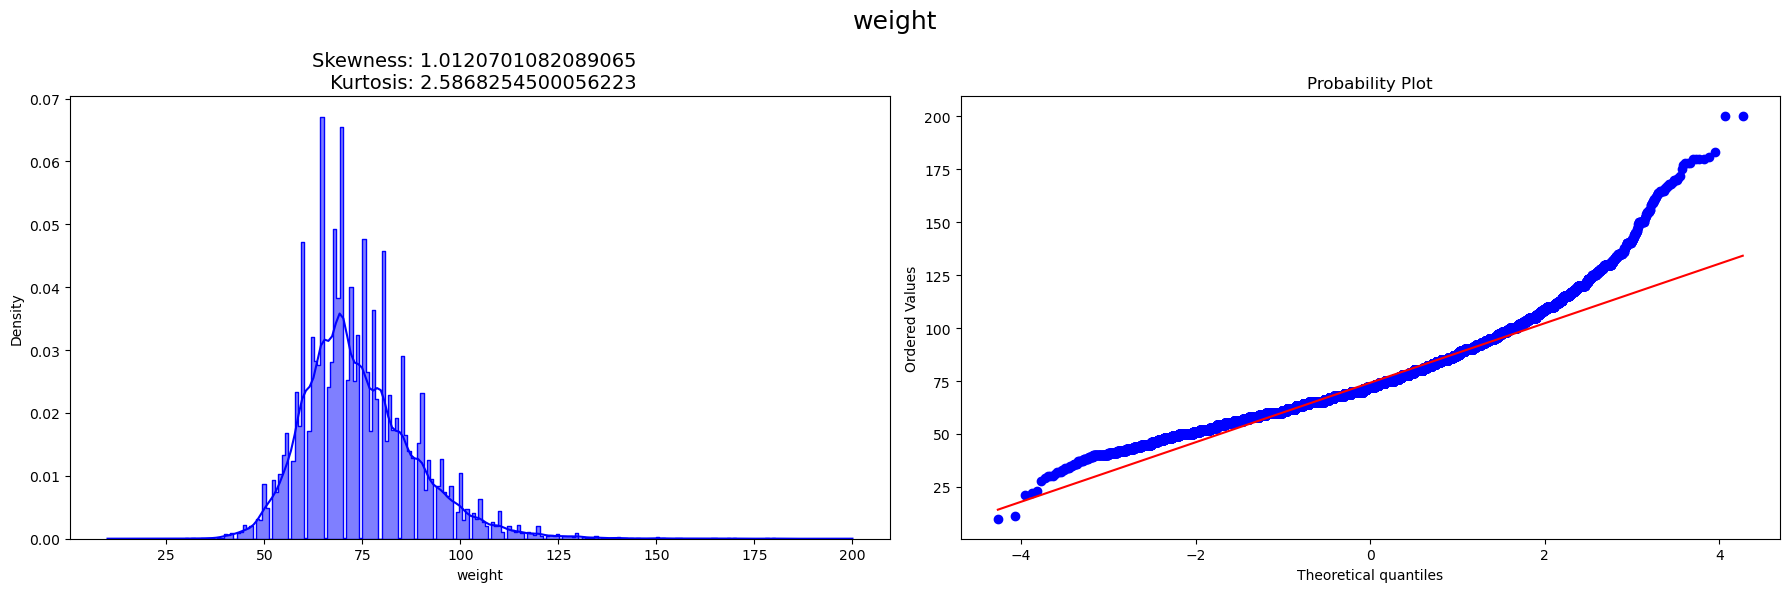

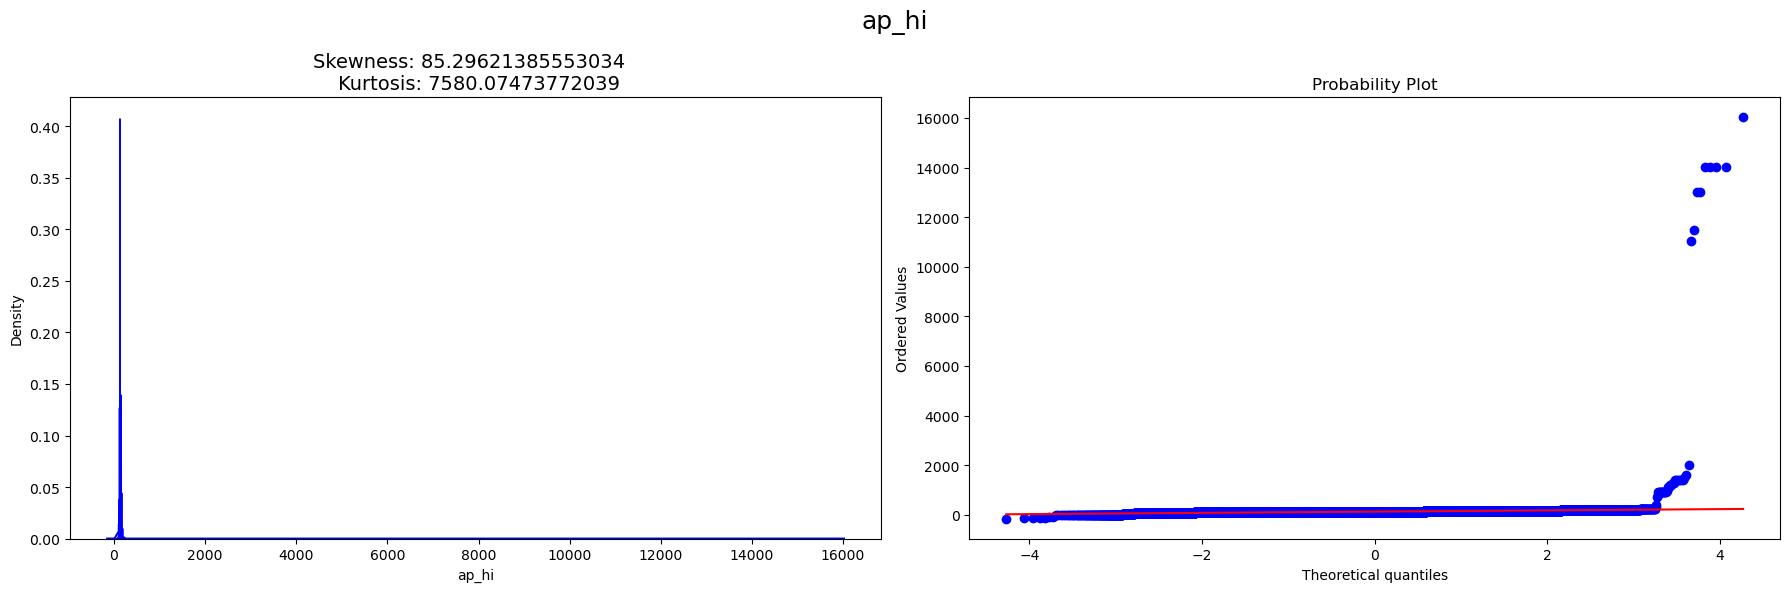

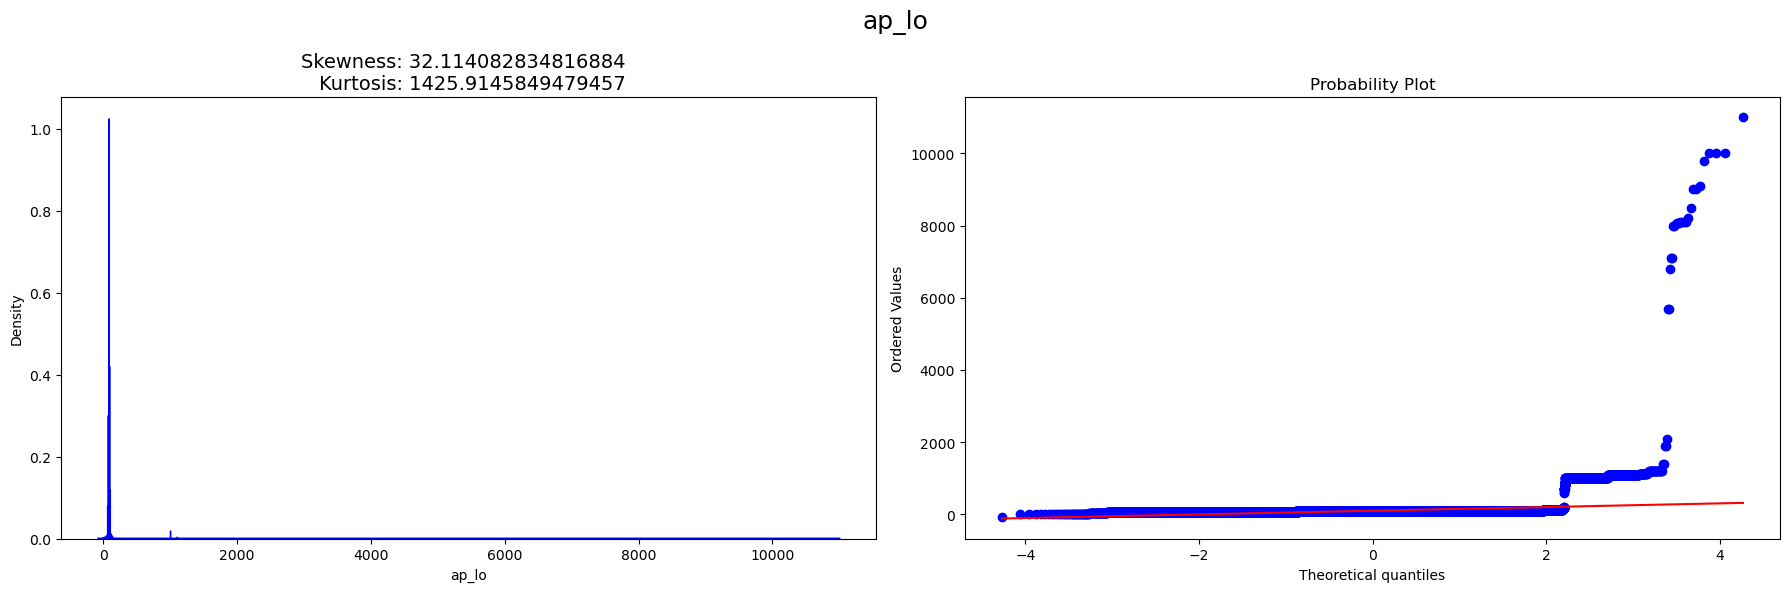

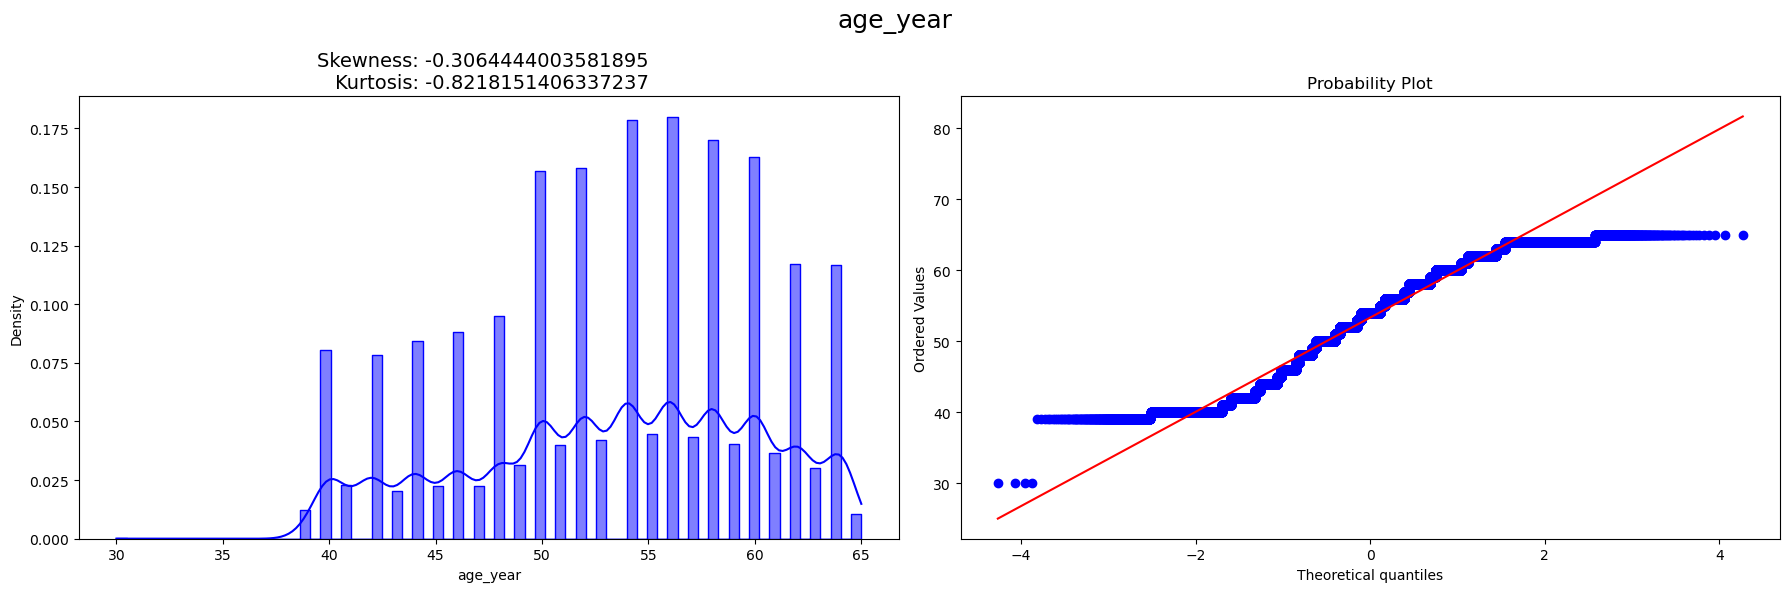

In [16]:
def plot(score):
    fig, ax = plt.subplots(1, 2,figsize=(18,6), dpi=100)
    sns.histplot(x=score, data=data, kde=True, element="step", stat="density",color ='blue' , ax=ax[0]) 
    
    stats.probplot(data.loc[:,score], plot = ax[1]) 
    ax[0].set_title(f"Skewness: {data[score].skew()}  \n Kurtosis: {data[score].kurt()}", fontsize=14, )
    
    plt.suptitle(score, fontsize=18)
    fig.tight_layout()
    plt.show()

for column in data_num:
    plot(column)

In [17]:
print(data_num['ap_hi'].max(), data_num['ap_lo'].max())
print(data_num['ap_hi'].min(), data_num['ap_lo'].min())

16020 11000
-150 -70


In [18]:
X = data[['height', 'weight', 'ap_hi', 'ap_lo', 'age_year', 
          'gender', 'cholesterol', 'gluc', 'smoke', 'alco', 
          'active']]
y = data[['cardio']]
X_train, X_test, y_train, y_test = train_test_split(X,y)

In [19]:
X.shape
y_train['cardio'].unique()

array([0, 1])

In [20]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.utils import class_weight

In [21]:
# dilatih dengan SVM
clf_svm = SVC(class_weight='balanced')
clf_svm.fit(X_train, y_train)
y_pred_svm = clf_svm.predict(X_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
confusion_matrix_svm = confusion_matrix(y_test, y_pred_svm)
print('Support Vector Machines : ')
print('Accuracy : ', accuracy_svm)
print("F1 Score : ", f1_svm)
print("Confusion Matrix:\n", confusion_matrix_svm)

Support Vector Machines : 
Accuracy :  0.7204571428571429
F1 Score :  0.6914343383373281
Confusion Matrix:
 [[7127 1577]
 [3315 5481]]


<Figure size 1000x800 with 0 Axes>

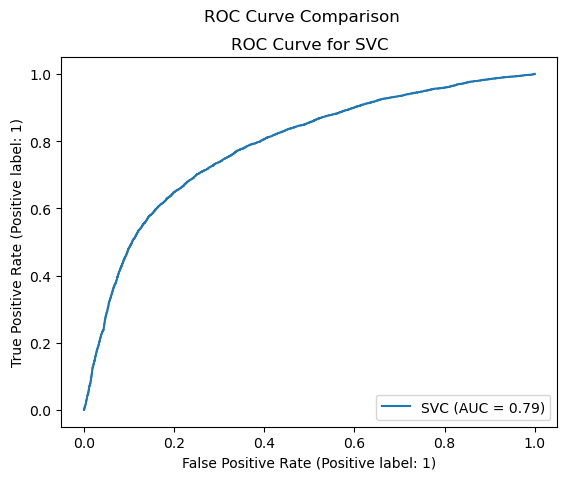

In [22]:
#ROC-AUC PLOT
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import plot_roc_curve
# List of classifiers
classifiers = [clf_svm,]

plt.figure(figsize=(10, 8))
for classifier in classifiers:
    disp = plot_roc_curve(classifier, X_test, y_test)
    disp.ax_.set_title('ROC Curve for {}'.format(classifier.__class__.__name__))

# Add title to the plot
plt.suptitle("ROC Curve Comparison")
plt.show()

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [24]:
data_pol = data[['smoke', 'active', 'alco', 'age_year', 'cholesterol']]

data_pol

,smoke,active,alco,age_year,cholesterol
0,0,1,0,50.0,1
1,0,1,0,55.0,3
2,0,0,0,52.0,3
3,0,1,0,48.0,1
4,0,0,0,48.0,1
...,...,...,...,...,...
69995,1,1,0,53.0,1
69996,0,1,0,62.0,2
69997,0,0,1,52.0,3
69998,0,0,0,61.0,1


In [25]:
data_pol.value_counts()

smoke  active  alco  age_year  cholesterol
0      1       0     54.0      1              3251
                     56.0      1              3134
                     50.0      1              3009
                     58.0      1              2882
                     52.0      1              2852
                                              ... 
1      0       0     41.0      2                 1
                               3                 1
                     65.0      2                 1
0      0       1     53.0      1                 1
1      0       1     46.0      3                 1
Length: 594, dtype: int64

In [26]:
data_pol.dtypes

smoke            int64
active           int64
alco             int64
age_year       float64
cholesterol      int64
dtype: object

Text(0.5, 1.0, 'Correlation')

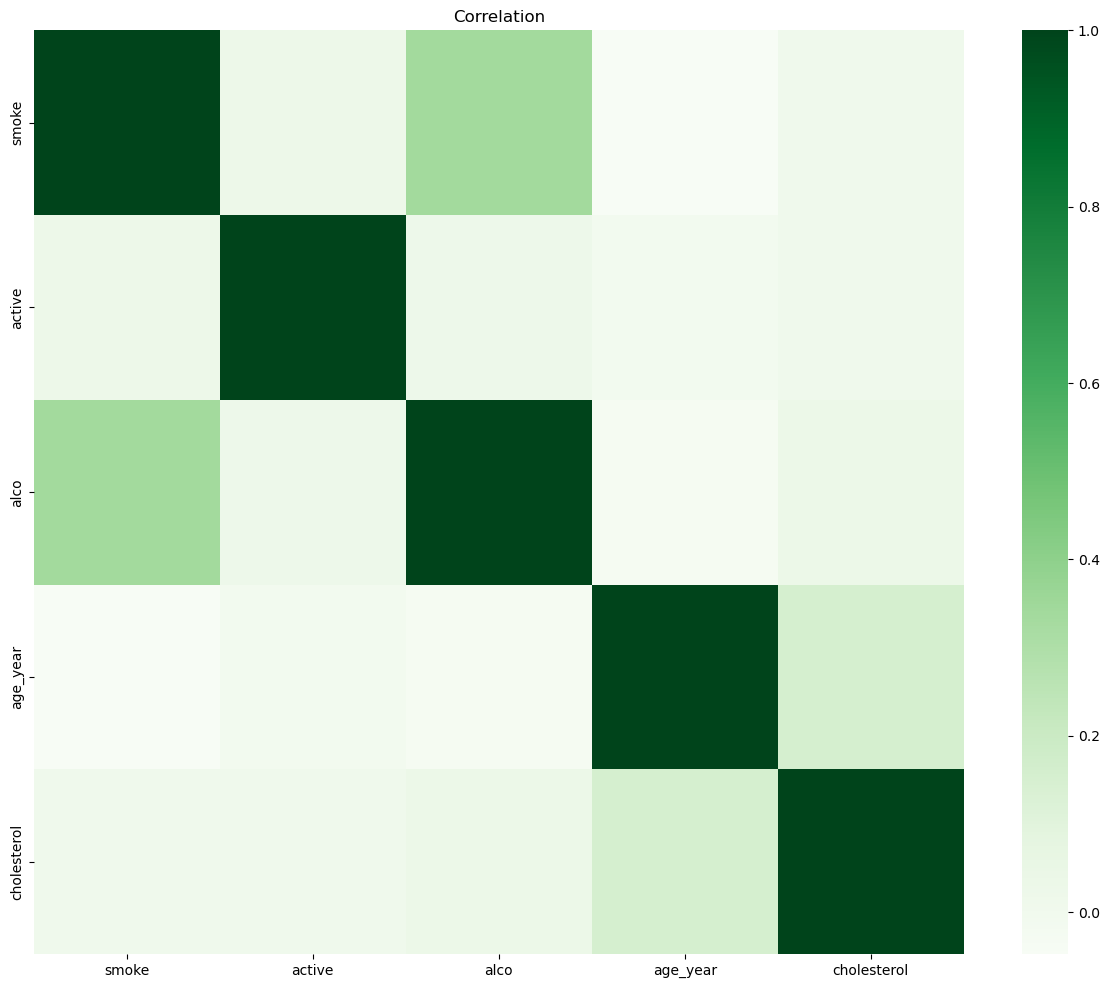

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
Pola=data_pol.corr()
fig = plt.figure(figsize=(15,12))
r = sns.heatmap(Pola, cmap='Greens')
r.set_title('Correlation')